In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns
#laoding the data using pandas 
df = pd.read_csv('time_series.csv')
#viewing the first 5 rows of the data to see how it looks
df.head(5)

,date,X1,X2,X3,X4,X5,X6,Y
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


In [2]:
#checking the data types of all columns to make sure that correct formats are used
df.dtypes

date     object
X1      float64
X2      float64
X3      float64
X4      float64
X5      float64
X6      float64
Y       float64
dtype: object

In [3]:
#converting date column into datetime format 
df['date'] = pd.to_datetime(df['date'])
#viewing the updated date format to see if it has worked
df.dtypes

date    datetime64[ns]
X1             float64
X2             float64
X3             float64
X4             float64
X5             float64
X6             float64
Y              float64
dtype: object

In [4]:
#making date column become the index of the table. This makes it easire to work with the data
df.set_index('date', inplace=True)
df.head(5)

,X1,X2,X3,X4,X5,X6,Y
date,,,,,,,
2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


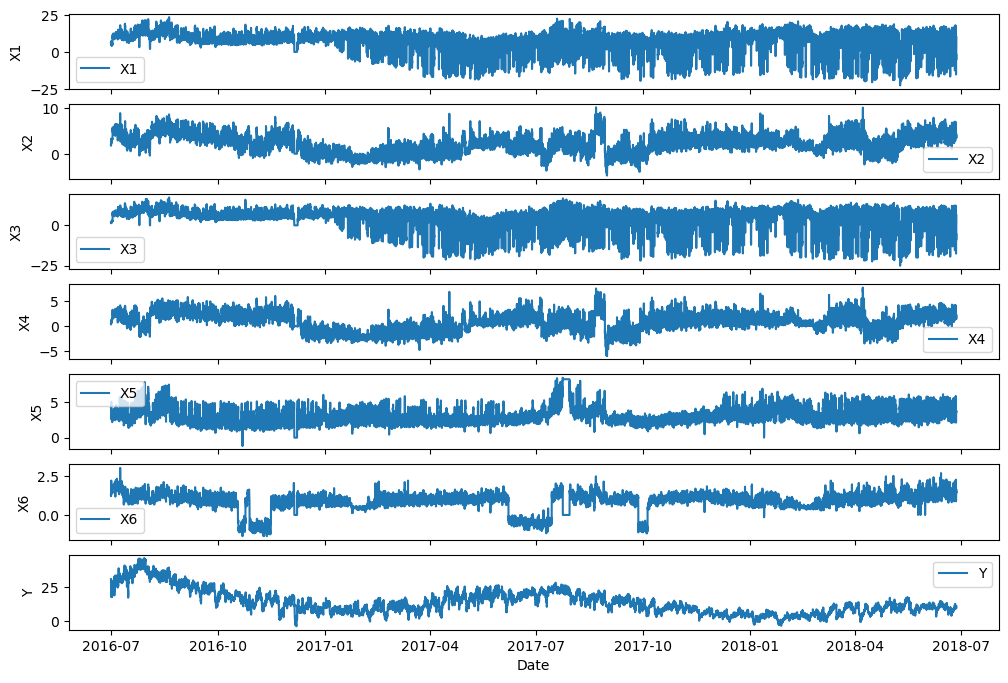

In [9]:
#plotting each variable to see how it is distributed
#ceating a subplot
fig, axes = plt.subplots(nrows=len(df.columns), ncols=1, figsize=(12, 8), sharex=True)
#looping through each column and plotting the data
for i, col in enumerate(df.columns):
    axes[i].plot(df.index, df[col], label=col)
    axes[i].set_ylabel(col)
    axes[i].legend()

plt.xlabel('Date')
plt.show()

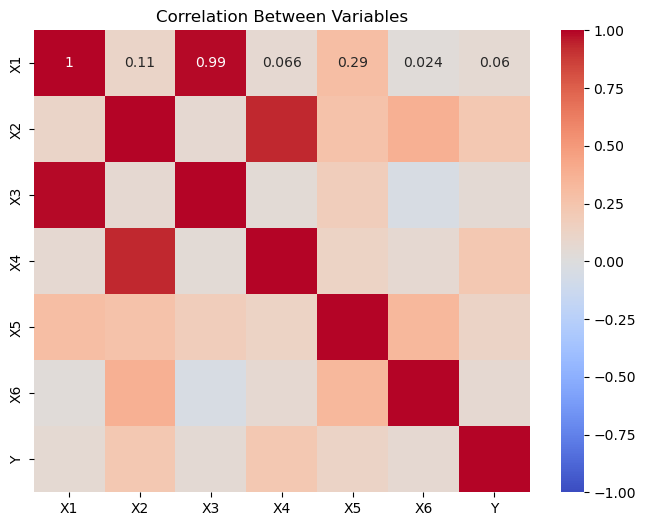

In [10]:
# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Variables")
plt.show()

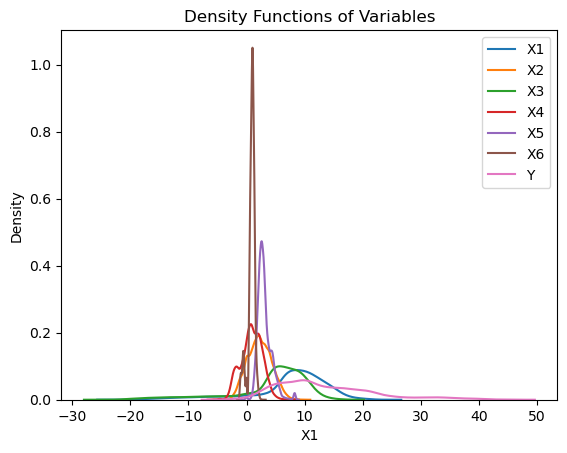

In [11]:
# Density plots
for col in df.columns:
    sns.kdeplot(df[col], label=col)
plt.title("Density Functions of Variables")
plt.legend()
plt.show()

In [12]:
#splitting the data
train_data = df['2016-07-01' : '2017-06-26']
validation_data = df['2017-06-27':'2017-10-24'] 
test_data = df['2017-10-25': '2018-02-21']

In [13]:
train_y = train_data['Y']
validation_y = validation_data['Y']
test_y = test_data['Y']

Text(0.5, 0, 'Time')

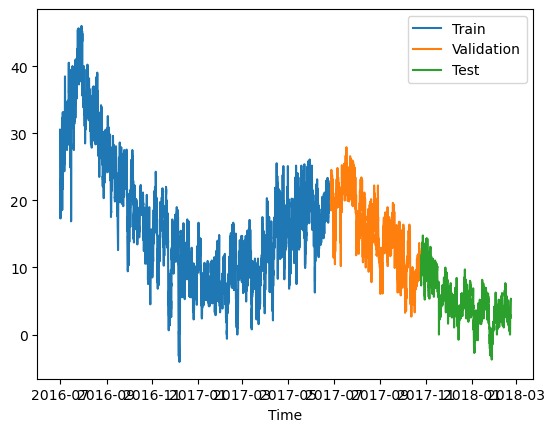

In [16]:
plt.plot(train_y, label= 'Train')
plt.plot(validation_y, label= 'Validation')
plt.plot(test_y, label= 'Test')
plt.legend()
plt.xlabel('Time')

In [35]:
# creating a scaler function

def standard_scaler(x_data, X_column):
    mean = np.mean(X_column)
    std_dev = np.std(X_column)
    z = (x_data - mean) / std_dev
    return z

In [36]:
#creating a new data empty datafarne to store the standardized data
train_data_standardized = pd.DataFrame()

for column in train_data.columns:
    train_data_standardized[column] = standard_scaler(train_data[column].values ,train_data[column] )
train_data_standardized

,X1,X2,X3,X4,X5,X6,Y
0,-0.362731,-0.005914,-0.630120,-0.149847,1.389276,0.876988,1.461431
1,-0.385794,0.026178,-0.649512,-0.168539,1.329613,0.925968,1.162039
2,-0.478047,-0.134281,-0.688116,-0.205403,0.972615,0.684229,1.162039
3,-0.489578,-0.038006,-0.688116,-0.186711,1.001957,0.780609,0.862756
4,-0.443452,-0.038006,-0.649512,-0.149847,1.061620,0.780609,0.524958
...,...,...,...,...,...,...,...
8659,0.271335,-0.326354,0.258674,0.496055,0.465971,-2.155028,0.256335
8660,0.490436,-0.390538,0.413270,0.256178,1.032277,-2.155028,0.310125
8661,0.317462,-0.486814,0.310146,0.532919,0.197977,-2.202428,0.340784
8662,0.248272,-0.262170,0.265017,0.329907,0.286982,-2.155028,0.317763


In [37]:
#checking if standardization has worked
print("Train mean (Y):", train_data_standardized['Y'].mean(), "std:", train_data_standardized['Y'].std())

Train mean (Y): 1.4795669562822536e-15 std: 1.0000577150607906


In [38]:
validation_data_standardized = pd.DataFrame()

for column in validation_data.columns:
    validation_data_standardized[column] = standard_scaler(validation_data[column].values ,validation_data[column] )

In [39]:
test_data_standardized = pd.DataFrame()

for column in test_data.columns:
    test_data_standardized[column] = standard_scaler(test_data[column].values ,test_data[column] )

In [40]:
#Implement matrix multiplication and inversion using numpy.
#selecting our matrix X and vector y from the train data

def LSE(X, y):
    # Concatenate a column of ones to X for the intercept term
    X_with_bias = np.c_[np.ones(X.shape[0]), X]  # shape (n_samples, n_features + 1)
    X_transpose = X_with_bias.T  # calculating x transpose
    beta = np.linalg.inv(X_transpose @ X_with_bias) @ (X_transpose @ y)
    return beta


X = train_data_standardized.iloc[:, : -1].values
y = train_data_standardized.iloc[:, -1].values


#Compute the estimated parameters using the LSE method.
beta = LSE(X, y)
print("Estimated parameters:", beta)

Estimated parameters: [ 5.29349411e-16 -3.15373366e-04  2.25661046e-01  1.46149538e-02
  3.10183880e-01  1.80987385e-01  1.47761850e-01]


In [53]:
# Predict on train, validation, and test sets
def predic_function(X, beta):
    X_with_bias = np.c_[np.ones(X.shape[0]), X]
    y_pred = X_with_bias @ beta
    return y_pred
#separeting label and variables
X_train = train_data_standardized.iloc[:, : -1].values
y_train = train_data_standardized.iloc[:, -1: ].values

X_validation = validation_data_standardized.iloc[:, : -1].values
y_validation = validation_data_standardized.iloc[:, -1: ].values

X_test = test_data_standardized.iloc[:, : -1].values
y_test = test_data_standardized.iloc[:,-1 : ].values

# predicting y for each section of the data
y_pred_train = predic_function(X_train, beta)
y_pred_validation = predic_function(X_validation, beta)
y_pred_test = predic_function(X_test, beta)

In [54]:
#Mean Squared Error (MSE)
def MSE(y, y_hat):
    mse_loss = np.mean((y - y_hat) ** 2)
    return mse_loss

#Root Mean Squared Error (RMSE)
def RMSE(y, y_hat):
    rmse_loss = np.sqrt(MSE(y, y_hat))
    return rmse_loss

In [55]:
train_MSE = MSE(y_train, y_pred_train)
train_RMSE = RMSE(y_train, y_pred_train)
print("Mean Squared Error:", train_MSE)
print("Root Mean Squared Error:", train_RMSE)

Mean Squared Error: 1.3987402890649085
Root Mean Squared Error: 1.182683511792106


In [56]:
validation_MSE = MSE(y_validation, y_pred_validation)
validation_RMSE = RMSE(y_validation, y_pred_validation)
print("Mean Squared Error:", validation_MSE)
print("Root Mean Squared Error:", validation_RMSE)

Mean Squared Error: 1.4036150351273549
Root Mean Squared Error: 1.184742602900459


In [57]:

test_MSE = MSE(y_test, y_pred_test)
test_RMSE = RMSE(y_test, y_pred_test)
print("Mean Squared Error:", test_MSE)
print("Root Mean Squared Error:", test_RMSE)

Mean Squared Error: 1.3750309955795914
Root Mean Squared Error: 1.172617156440921


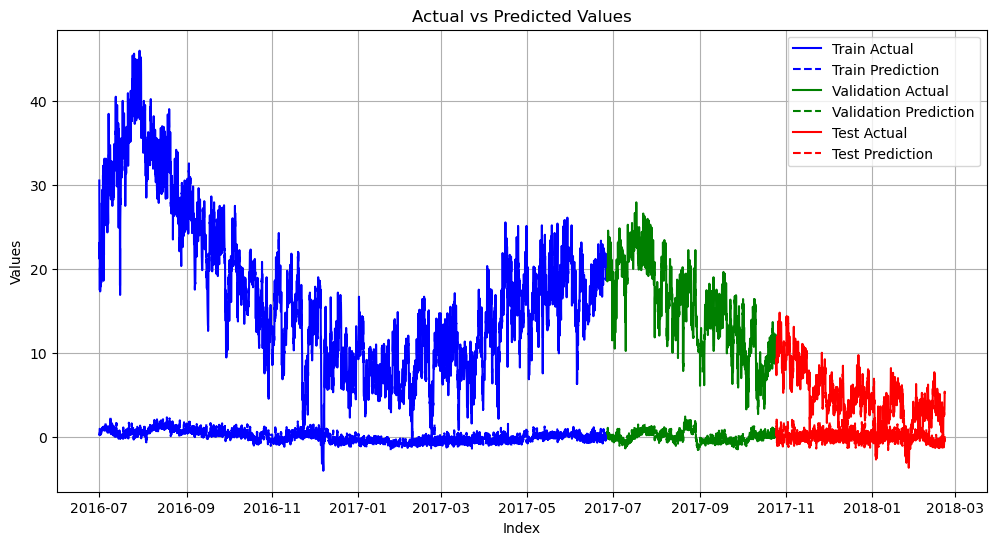

In [60]:
# Plot training, validation, and test data with predictions
plt.figure(figsize=(12, 6))

# Plot training data and predictions
plt.plot(train_y.index, train_y, label="Train Actual", color="blue", linestyle="-")
plt.plot(train_y.index, y_pred_train, label="Train Prediction", color="blue", linestyle="--")

# Plot validation data and predictions
plt.plot(validation_y.index, validation_y, label="Validation Actual", color="green", linestyle="-")
plt.plot(validation_y.index, y_pred_validation, label="Validation Prediction", color="green", linestyle="--")

# Plot test data and predictions
plt.plot(test_y.index, test_y, label="Test Actual", color="red", linestyle="-")
plt.plot(test_y.index, y_pred_test, label="Test Prediction", color="red", linestyle="--")

# Formatting the plot
plt.title("Actual vs Predicted Values")
plt.xlabel("Index")
plt.ylabel("Values")
plt.legend()
plt.grid(True)

plt.show()

In [47]:
#Visualizing Least Squares Estimation on a Toy Dataset

toy_data = pd.read_csv("toy_data.csv")
toy_data.head(10)

,X1,X2,Y
0,5.530492,8.136530,53.470131
1,5.111720,0.846906,15.925409
2,9.011047,6.510469,54.649639
3,7.806497,0.349096,24.003095
4,2.047190,1.057417,14.739897
5,3.640398,8.856639,55.696555
6,0.973068,4.879262,28.903875
7,6.321576,4.464032,35.481217
8,2.420427,7.237535,41.646911
9,5.451504,8.074263,53.899325


In [48]:
toy_data.shape

(100, 3)

In [49]:
X = toy_data.iloc[:, : -1].values
y = toy_data.iloc[ : , -1:].values

In [50]:
# Compute the estimated parameters using the LSE method.
toy_beta = LSE(X, y)
print("Estimated parameters:", toy_beta)

Estimated parameters: [[3.66345247]
 [1.96836519]
 [4.93212246]]


In [51]:
y_hat = predic_function(X, toy_beta)

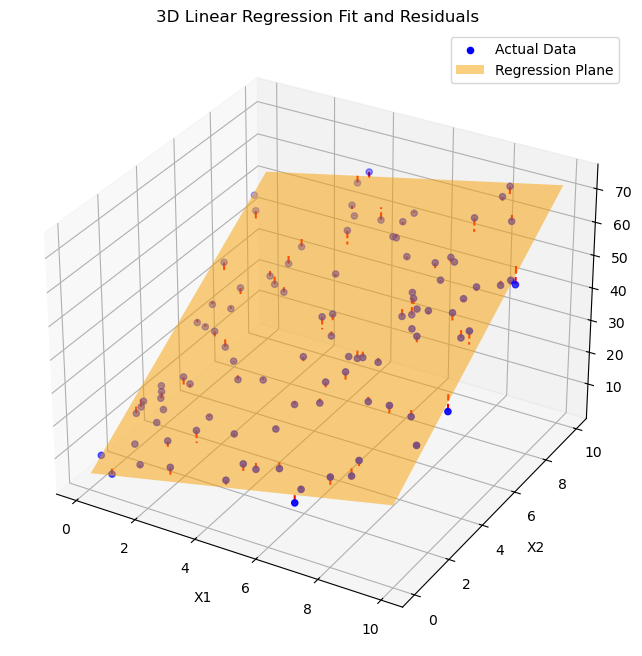

In [52]:
from mpl_toolkits.mplot3d import Axes3D

# Create a 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot of actual data points
scat = ax.scatter(toy_data['X1'], toy_data['X2'], toy_data['Y'], color='blue', label='Actual Data')

# Create a meshgrid for the regression plane
x1_range = np.linspace(toy_data['X1'].min(), toy_data['X1'].max(), 10)
x2_range = np.linspace(toy_data['X2'].min(), toy_data['X2'].max(), 10)
x1_mesh, x2_mesh = np.meshgrid(x1_range, x2_range)
y_mesh = toy_beta[0] + toy_beta[1] * x1_mesh + toy_beta[2] * x2_mesh  # Regression plane

# Plot the regression plane
plane = ax.plot_surface(x1_mesh, x2_mesh, y_mesh, color='orange', alpha=0.5, rstride=100, cstride=100)

# Plot residuals
for i in range(len(y)):
    ax.plot([X[i, 0], X[i, 0]], [X[i, 1], X[i, 1]], [y[i, 0], y_hat[i, 0]], 'r--', label='Residuals' if i == 0 else "")

# Labels and legend
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('Y')
ax.legend([scat, plane], ['Actual Data', 'Regression Plane'], loc='best')
ax.set_title('3D Linear Regression Fit and Residuals')

plt.show()
